# 1. Data Creation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data Splitting & Preprocessing
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Machine Learning Models - SWITCHING TO XGBOOST
from xgboost import XGBClassifier

# Evaluation Metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, precision_recall_curve, f1_score

# For SHAP values (Interpretability)
import shap

In [2]:
import pandas as pd
import numpy as np
import random
random.seed(42)
np.random.seed(42)

# --- 1. Define the Categories ---
occupations = ['Salaried', 'Self-Employed', 'Farmer', 'Daily-Wage', 'Professional', 'Student']
loan_types = ['Personal', 'SME/Business', 'Agricultural', 'Emergency', 'Education', 'Professional']
channels = ['Social_Media', 'Referral', 'Direct_App', 'Partner_Agent']
devices = ['Premium', 'Mid-range', 'Budget']

# --- 2. The Logic Function (Creates 1 user with realistic patterns) ---
def generate_user(user_id):
    # A. Profile & Occupation
    occ = random.choice(occupations)
    age = random.randint(18, 65)

    # B. Income & Credit Score (Linked to Occupation)
    if occ == 'Daily-Wage':
        income = random.randint(8000, 20000)
        credit_score = random.randint(300, 600)
        loan_type = 'Emergency'
    elif occ == 'Farmer':
        income = random.randint(10000, 35000)
        credit_score = random.randint(400, 650)
        loan_type = 'Agricultural'
    elif occ == 'Salaried':
        income = random.randint(25000, 150000)
        credit_score = random.randint(550, 800)
        loan_type = 'Personal'
    elif occ == 'Self-Employed':
        income = random.randint(20000, 100000)
        credit_score = random.randint(500, 750)
        loan_type = 'SME/Business'
    elif occ == 'Professional':
        income = random.randint(80000, 300000)
        credit_score = random.randint(700, 850)
        loan_type = 'Professional'
    else: # Student
        income = random.randint(0, 15000)
        credit_score = random.randint(500, 700)
        loan_type = 'Education'

    # C. Loan Details (Linked to Loan Type)
    if loan_type == 'Emergency':
        amount = random.randint(5000, 50000)
        tenure = random.choice([3, 6])
        rate = round(random.uniform(18.0, 28.0), 2)

    elif loan_type == 'Agricultural':
        amount = random.randint(100000, 2000000)
        tenure = random.randint(12, 36)
        rate = round(random.uniform(11.0, 16.0), 2)

    elif loan_type == 'SME/Business':
        amount = random.randint(100000, 2000000)
        tenure = random.randint(12, 36)
        rate = round(random.uniform(16.0, 24.0), 2)

    else:
        amount = random.randint(50000, 500000)
        tenure = random.randint(6, 60)
        rate = round(random.uniform(10.0, 18.0), 2)

    # D. Behavioral / Alternative Signals
    channel = random.choice(channels)
    apps_installed = random.choices([0, 1, 2, 3, 4, 5], weights=[30, 25, 20, 15, 7, 3])[0]
    app_time = random.randint(0, 23)
    cashflow_shock = random.choices([0, 1], weights=[80, 20])[0]
    app_drop = random.choices([0, 1], weights=[85, 15])[0]

    # E. Calculate "Hidden Risk Score" to determine Default
    risk_score = 50 # Base score

    # Red flags (Increase risk)
    if credit_score < 600: risk_score += 15
    if apps_installed >= 3: risk_score += 20
    if app_time >= 1 and app_time <= 4: risk_score += 10
    if cashflow_shock == 1: risk_score += 15
    if app_drop == 1: risk_score += 10
    if income < 20000: risk_score += 10

    # Green flags (Decrease risk)
    if credit_score > 750: risk_score -= 20
    if occ == 'Professional': risk_score -= 15

    # F. Determine Target (Default Flag) based on Risk Score
    default_prob = (risk_score - 30) / 100
    default_prob = max(0.05, min(0.95, default_prob))

    is_default = 1 if random.random() < default_prob else 0

    # Days past due & Months to Default
    if is_default == 1:
        days_past_due = random.randint(1, 120)
        # NEW: Assign months to default based on risk severity
        if risk_score > 75:
            months_to_default = random.randint(1, 3) # Fast default
        elif risk_score > 60:
            months_to_default = random.randint(4, 6)
        else:
            months_to_default = random.randint(7, 12)
    else:
        days_past_due = 0
        months_to_default = np.nan

    # G. Feature Engineering (Calculated Columns)
    debt_to_income_ratio = amount / (income + 1)

    # EMI Burden Calculation
    r = rate / 12 / 100
    n = tenure
    if r == 0:
        emi = amount / n
    else:
        emi = (amount * r * (1 + r)**n) / ((1 + r)**n - 1)
    emi_burden = emi / (income + 1)

    # Risk Category Label
    if risk_score > 75: risk_category = 'High'
    elif risk_score > 50: risk_category = 'Medium'
    else: risk_category = 'Low'

    # Return as a dictionary
    return {
        'customer_id': f'CUST_{user_id:04d}',
        'age': age,
        'occupation': occ,
        'monthly_income': income,
        'credit_score': credit_score,
        'loan_type': loan_type,
        'loan_amount': amount,
        'tenure_months': tenure,
        'interest_rate': rate,
        'acquisition_channel': channel,
        'loan_apps_installed': apps_installed,
        'application_time_hour': app_time,
        'cashflow_shock': cashflow_shock,
        'app_engagement_drop': app_drop,
        'default_flag': is_default,
        'days_past_due': days_past_due,
        'months_to_default': months_to_default,
        'debt_to_income_ratio': debt_to_income_ratio,
        'emi_burden': emi_burden,
        'risk_category': risk_category
    }

# 3. Generate 1,000 Users
print("Generating 1,000 synthetic users with advanced features...")
data = [generate_user(i) for i in range(1, 1001)]
df = pd.DataFrame(data)

# 4. Save to CSV
df.to_csv('lending_portfolio_data.csv', index=False)
print("Dataset created and saved as 'lending_portfolio_data.csv'")
print(f"Columns added: {['debt_to_income_ratio', 'emi_burden', 'risk_category', 'months_to_default']}")

Generating 1,000 synthetic users with advanced features...
Dataset created and saved as 'lending_portfolio_data.csv'
Columns added: ['debt_to_income_ratio', 'emi_burden', 'risk_category', 'months_to_default']


In [3]:
# Check total rows
print(f"Total rows: {len(df)}")
print(f"Dataset shape: {df.shape}")

Total rows: 1000
Dataset shape: (1000, 20)


In [4]:
# See rows 50-60
df.iloc[50:60].round(2)

,customer_id,age,occupation,monthly_income,credit_score,loan_type,loan_amount,tenure_months,interest_rate,acquisition_channel,loan_apps_installed,application_time_hour,cashflow_shock,app_engagement_drop,default_flag,days_past_due,months_to_default,debt_to_income_ratio,emi_burden,risk_category
50,CUST_0051,24,Self-Employed,59529,717,SME/Business,1534995,31,22.44,Social_Media,1,13,0,0,0,0,NaN,25.79,1.10,Low
51,CUST_0052,44,Salaried,132784,675,Personal,105332,33,17.69,Partner_Agent,2,13,0,0,0,0,NaN,0.79,0.03,Low
52,CUST_0053,52,Professional,283067,823,Professional,293727,33,16.61,Direct_App,1,7,1,0,0,0,NaN,1.04,0.04,Low
53,CUST_0054,47,Self-Employed,94691,656,SME/Business,1501292,24,18.69,Partner_Agent,3,5,0,0,1,36,6.0,15.85,0.80,Medium
54,CUST_0055,35,Student,9106,502,Education,320861,18,10.68,Partner_Agent,1,7,0,0,0,0,NaN,35.23,2.13,Medium
55,CUST_0056,23,Salaried,63566,606,Personal,262022,50,11.95,Direct_App,1,16,0,1,0,0,NaN,4.12,0.11,Medium
56,CUST_0057,62,Farmer,24868,469,Agricultural,743035,20,12.15,Referral,1,23,0,0,1,28,6.0,29.88,1.66,Medium
57,CUST_0058,35,Daily-Wage,19871,568,Emergency,44111,6,27.81,Referral,0,11,0,0,0,0,NaN,2.22,0.40,Medium
58,CUST_0059,20,Farmer,11786,541,Agricultural,712654,34,15.72,Partner_Agent,0,0,0,0,1,24,4.0,60.46,2.22,Medium
59,CUST_0060,48,Farmer,13738,610,Agricultural,237035,24,13.46,Social_Media,0,18,1,0,1,72,5.0,17.25,0.82,Medium


In [5]:
# loaded the dataset
df = pd.read_csv('lending_portfolio_data.csv')

### 1.1 defining the X and y

In [6]:
# setting the X and y values here

X = df.drop(columns = ['customer_id', 'default_flag' , 'days_past_due' , 'months_to_default']) # all columns included , except these three mentioned her e
y = df['default_flag'] # only the default flag as its gonna be pritning 0 and 1 for whether the user is default or not

print(f"Features : X shape is {X.shape}")
print(f"Labels : y shape is {y.shape}")


Features : X shape is (1000, 16)
Labels : y shape is (1000,)


### 1.2 dataset transformation into numerical

In [7]:
# converting columns i.e the text categories into the numbers

from sklearn.preprocessing import LabelEncoder

categorical_columns = X.select_dtypes(include= ['object']).columns.tolist()

for column in categorical_columns:
  le = LabelEncoder()
  X[column]  = le.fit_transform(X[column])



In [8]:
# --- ENHANCED PREPROCESSING: OUTLIER CAPPING + FEATURE BINNING ---
from sklearn.preprocessing import LabelEncoder

print("="*60)
print("STEP 1: OUTLIER CAPPING ON ENGINEERED FEATURES")
print("="*60)

# Cap extreme outliers that break tree splits
outlier_cols = ['debt_to_income_ratio', 'emi_burden']
for col in outlier_cols:
    upper_limit = X[col].quantile(0.99)
    X[col] = X[col].clip(upper=upper_limit)
    print(f"✓ {col} capped at {upper_limit:.2f}")

print("\n" + "="*60)
print("STEP 2: CREDIT SCORE BINNING (Helps trees capture thresholds)")
print("="*60)

# Bin credit_score into meaningful FICO-like ranges
bins = [0, 580, 660, 720, 800, 900]
labels = ['Very_Poor', 'Poor', 'Fair', 'Good', 'Excellent']
X['credit_score_bin'] = pd.cut(X['credit_score'], bins=bins, labels=labels, include_lowest=True)

# Encode the new binned column
le_bin = LabelEncoder()
X['credit_score_bin'] = le_bin.fit_transform(X['credit_score_bin'])
print(f"✓ Credit score binned into {len(labels)} categories")
print(f"✓ New feature count: {X.shape[1]} (was 16)")

print("\nPreprocessing complete. Ready for splitting.")

STEP 1: OUTLIER CAPPING ON ENGINEERED FEATURES
✓ debt_to_income_ratio capped at 490.37
✓ emi_burden capped at 25.11

STEP 2: CREDIT SCORE BINNING (Helps trees capture thresholds)
✓ Credit score binned into 5 categories
✓ New feature count: 17 (was 16)

Preprocessing complete. Ready for splitting.


### 1.3 Checking up on the data after conversion

In [9]:
# checking here , as the text is converted into the data values now
display(X.head())

,age,occupation,monthly_income,credit_score,loan_type,loan_amount,tenure_months,interest_rate,acquisition_channel,loan_apps_installed,application_time_hour,cashflow_shock,app_engagement_drop,debt_to_income_ratio,emi_burden,risk_category,credit_score_bin
0,25,5,409,689,1,194194,21,11.79,3,2,17,0,0,473.643902,25.071431,2,1
1,56,2,86956,843,4,154248,51,15.20,1,0,18,0,1,1.773842,0.047429,1,0
2,62,4,75392,587,5,682738,16,17.72,0,0,12,0,0,9.055721,0.639624,2,3
3,64,3,85217,687,3,115444,30,10.63,0,3,19,1,0,1.354690,0.051620,0,1
4,32,5,12665,574,1,91833,60,11.86,3,1,14,0,0,7.250355,0.160768,2,4


In [10]:
display(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   customer_id            1000 non-null   object 
 1   age                    1000 non-null   int64  
 2   occupation             1000 non-null   object 
 3   monthly_income         1000 non-null   int64  
 4   credit_score           1000 non-null   int64  
 5   loan_type              1000 non-null   object 
 6   loan_amount            1000 non-null   int64  
 7   tenure_months          1000 non-null   int64  
 8   interest_rate          1000 non-null   float64
 9   acquisition_channel    1000 non-null   object 
 10  loan_apps_installed    1000 non-null   int64  
 11  application_time_hour  1000 non-null   int64  
 12  cashflow_shock         1000 non-null   int64  
 13  app_engagement_drop    1000 non-null   int64  
 14  default_flag           1000 non-null   int64  
 15  days_

None

In [11]:
df['loan_type'].unique()

array(['Education', 'Professional', 'SME/Business', 'Personal',
       'Agricultural', 'Emergency'], dtype=object)

In [12]:
for i, category in enumerate(df['loan_type'].unique()):
  print(i ,{category})

0 {'Education'}
1 {'Professional'}
2 {'SME/Business'}
3 {'Personal'}
4 {'Agricultural'}
5 {'Emergency'}


In [13]:
for i , category in enumerate(df['occupation'].unique()):
  print(i , {category})

0 {'Student'}
1 {'Professional'}
2 {'Self-Employed'}
3 {'Salaried'}
4 {'Farmer'}
5 {'Daily-Wage'}


In [14]:
df.describe().round()

,age,monthly_income,credit_score,loan_amount,tenure_months,interest_rate,loan_apps_installed,application_time_hour,cashflow_shock,app_engagement_drop,default_flag,days_past_due,months_to_default,debt_to_income_ratio,emi_burden
count,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,359.0,1000.0,1000.0
mean,42.0,63026.0,609.0,500631.0,26.0,16.0,2.0,12.0,0.0,0.0,0.0,22.0,4.0,63.0,4.0
std,14.0,70056.0,126.0,533536.0,16.0,4.0,1.0,7.0,0.0,0.0,0.0,36.0,3.0,620.0,58.0
min,18.0,17.0,303.0,5242.0,3.0,10.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
25%,29.0,12830.0,529.0,128620.0,13.0,13.0,0.0,6.0,0.0,0.0,0.0,0.0,2.0,2.0,0.0
50%,42.0,32091.0,610.0,314152.0,25.0,15.0,1.0,12.0,0.0,0.0,0.0,0.0,4.0,7.0,1.0
75%,53.0,92906.0,706.0,555773.0,35.0,19.0,2.0,18.0,0.0,0.0,1.0,39.0,6.0,33.0,2.0
max,65.0,299990.0,850.0,1991507.0,60.0,28.0,5.0,23.0,1.0,1.0,1.0,120.0,12.0,16666.0,1752.0


# Data Splitting

In [15]:
from sklearn.model_selection import train_test_split

X_train , X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.3,
    random_state = 42,
    stratify = y
)

X_train.shape , X_test.shape , y_train.shape , y_test.shape

((700, 17), (300, 17), (700,), (300,))

In [16]:
print(f"defualt rate - training : {y_train.mean().round(2)}")

print(f"defualt rate - testing : {y_test.mean().round(2)}")

defualt rate - training : 0.36
defualt rate - testing : 0.36


In [17]:
print(X_train.shape[0])

700


# 3 Model training and using stratified K-fold



### 3.1

1. ROC-AUC
*  measuring how well the the model ranks the risky customers above safe ones , 0.5 is random  guessing , 1 is prefect .
* this will tell us the that how much model is currently struggling to distinguish defaulters from non-defaulters with the current features

2. F1-Score
* a balance of precision and recall , it tells us that when the model will  predicts default (considerening both false positives and false negatives ).

In [18]:
from sklearn.model_selection import StratifiedKFold
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score , f1_score
import numpy as np

# 1. initializing the stratifiedKFold ,creating(5 folds) for 5 different performances
skf = StratifiedKFold(n_splits = 5 , shuffle = True , random_state = 42)

# 2. create storage lists for metrics
fold_roc_auc  = [] # fold receiver operating characteristic
fold_f1 = [] # fold_f1

# used the skf.split() for the randomized list of specific row numbers
for fold , (train_idx, val_idx) in enumerate(skf.split(X_train, y_train)):
  X_training_fold = X_train.iloc[train_idx]
  y_training_fold = y_train.iloc[train_idx]

  X_validation_fold = X_train.iloc[val_idx]
  y_validation_fold = y_train.iloc[val_idx]


  n_negative = (y_training_fold == 0).sum()
  n_positive = (y_training_fold == 1).sum()
  weight = n_negative/n_positive

  model = XGBClassifier(
      n_estimators = 300,
      max_depth = 3,
      learning_rate = 0.02,
      min_child_weight = 10,
      subsample= 0.8,
      colsample_bytree = 0.8,
      scale_pos_weight= weight,# weight = (no. of safe sutomers) / (no. of defaulters)
      eval_metric = 'auc',
      use_label_encoder = False,
      random_state = 42,
      verbosity = 0
  )

  model.fit(X_training_fold , y_training_fold)

  y_validation_prob = model.predict_proba(X_validation_fold)[:,1]
  y_validation_pred = (y_validation_prob > 0.5).astype(int)


  roc_auc = roc_auc_score(y_validation_fold, y_validation_prob)
  f1 = f1_score(y_validation_fold , y_validation_pred)

  fold_roc_auc.append(roc_auc)
  fold_f1.append(f1)

  print(f"Fold {fold+1} : ROC-AUC = {roc_auc:.4f} | F1 = {f1:.4f} ")

print("\n" + "="*60)
print(f"Final CV Results : ")
print(f"ROC-AUC : {np.mean(fold_roc_auc):.4f} ± {np.std(fold_roc_auc):.4f}")
print(f"F1-Score: {np.mean(fold_f1):.4f} ± {np.std(fold_f1):.4f}")


Fold 1 : ROC-AUC = 0.7147 | F1 = 0.5391 
Fold 2 : ROC-AUC = 0.7158 | F1 = 0.5439 
Fold 3 : ROC-AUC = 0.6467 | F1 = 0.4630 
Fold 4 : ROC-AUC = 0.6884 | F1 = 0.5625 
Fold 5 : ROC-AUC = 0.6116 | F1 = 0.4918 

Final CV Results : 
ROC-AUC : 0.6754 ± 0.0406
F1-Score: 0.5201 ± 0.0369


### 3.2 training the final model on full training set

In [19]:
from sklearn.metrics import roc_auc_score , f1_score , classification_report

final_scale_pos_weight = (y_train == 0 ).sum() / (y_train == 1).sum()

final_model = XGBClassifier(
    n_estimators = 300 ,
    max_depth = 3,
    min_child_weight = 10,
    subsample = 0.8,
    colsample_bytree = 0.8,
    learning_rate = 0.03,
    scale_pos_weight = final_scale_pos_weight,
    eval_metric = 'auc',
    use_label_encoder = False,
    random_state = 42 ,
    verbosity = 0

)

final_model.fit(X_train , y_train)
print("final model trained successfully ")


print("now evaluating on hold out test set ")

y_test_prob = final_model.predict_proba(X_test)[:,1]
y_test_pred = (y_test_prob > 0.5).astype(int)

test_roc_auc = roc_auc_score(y_test ,y_test_prob)
test_f1 = f1_score(y_test, y_test_pred)

print(f"testing set roc - auc : {test_roc_auc:.4f}")
print(f"Test Set F1-Score: {test_f1:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, target_names=['Non-Defaulter', 'Defaulter']))

final model trained successfully 
now evaluating on hold out test set 
testing set roc - auc : 0.7278
Test Set F1-Score: 0.5863

Classification Report:
               precision    recall  f1-score   support

Non-Defaulter       0.78      0.65      0.71       192
    Defaulter       0.52      0.68      0.59       108

     accuracy                           0.66       300
    macro avg       0.65      0.66      0.65       300
 weighted avg       0.69      0.66      0.66       300



# 4 SHAP INTERPRETABILITY

GENERATING PRESENTATION-READY VISUALIZATIONS

1. CONFUSION MATRIX
------------------------------------------------------------


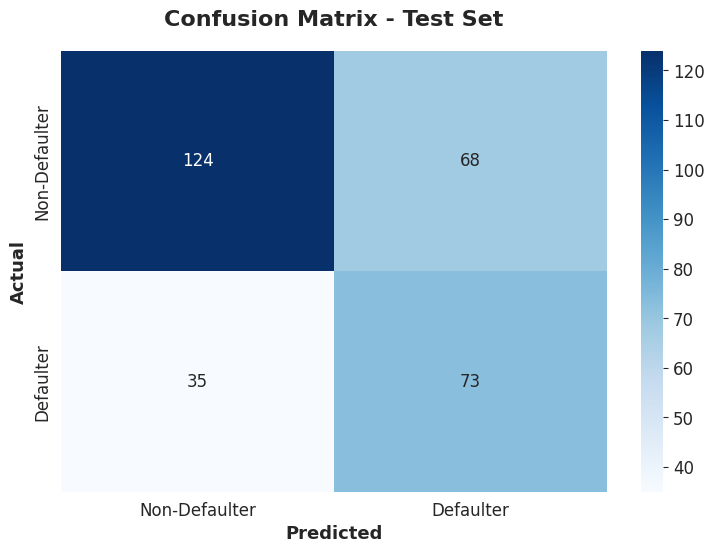


2. ROC CURVE
------------------------------------------------------------


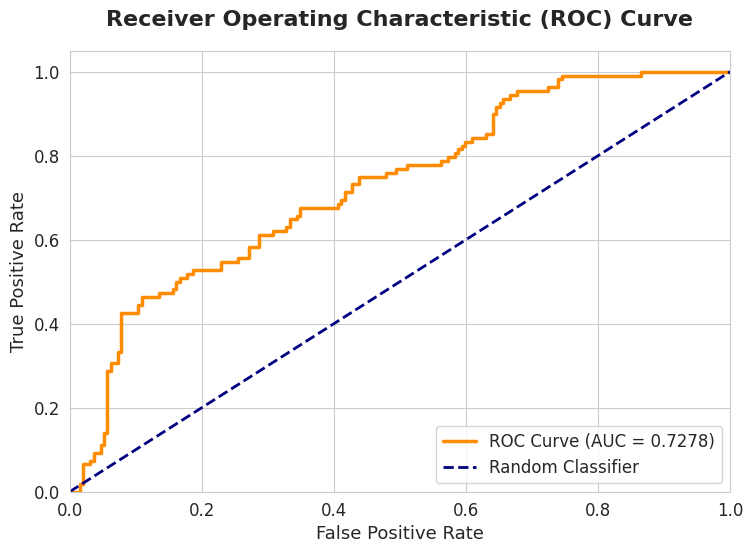


3. PRECISION-RECALL CURVE
------------------------------------------------------------


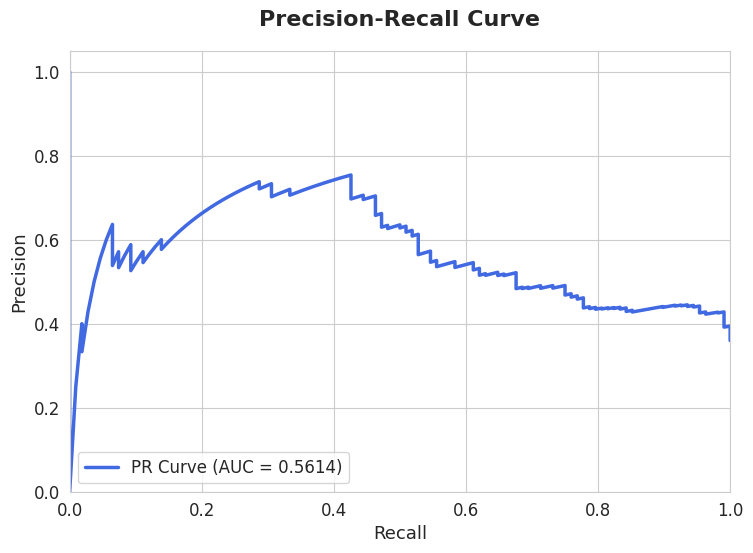


4. SHAP EXPLANATIONS
------------------------------------------------------------

4A. TOP 10 FEATURE IMPORTANCE (SHAP)


/tmp/ipykernel_16252/681781897.py:101: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test, plot_type='bar', max_display=10, show=False)


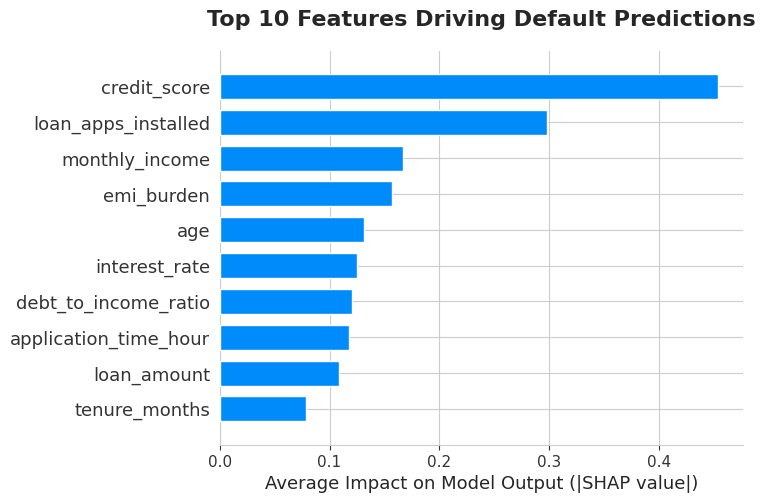


4B. FEATURE IMPACT DIRECTION


/tmp/ipykernel_16252/681781897.py:114: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test, max_display=10, show=False)


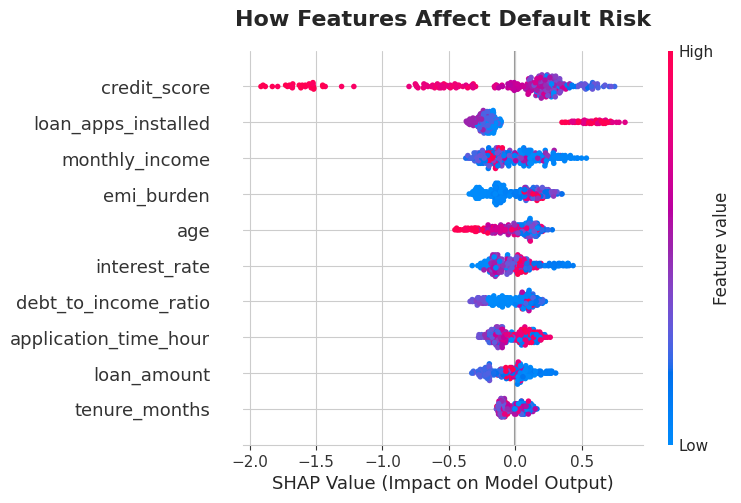


5. INDIVIDUAL PREDICTION BREAKDOWNS
------------------------------------------------------------

Customer 484 | Actual: Defaulter | Predicted default probability: 66.2%


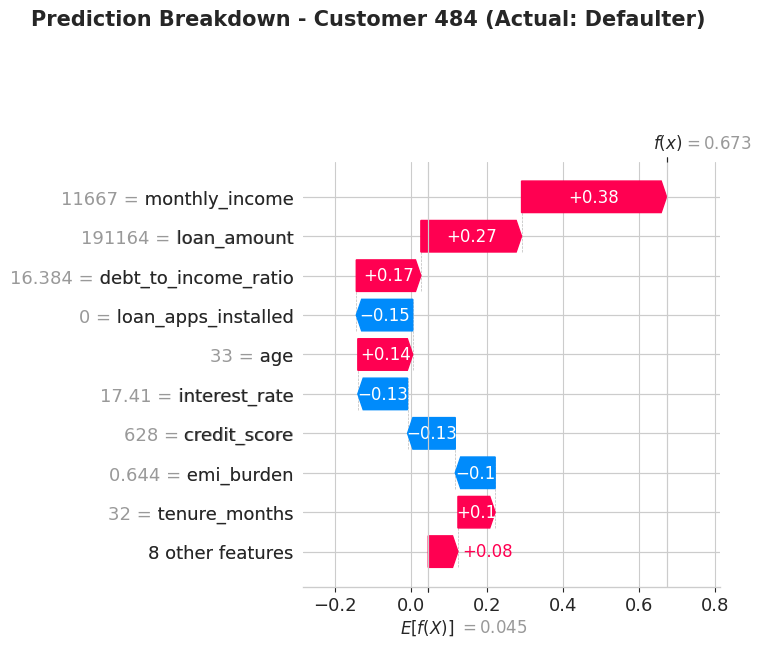


Customer 816 | Actual: Non-Defaulter | Predicted default probability: 14.2%


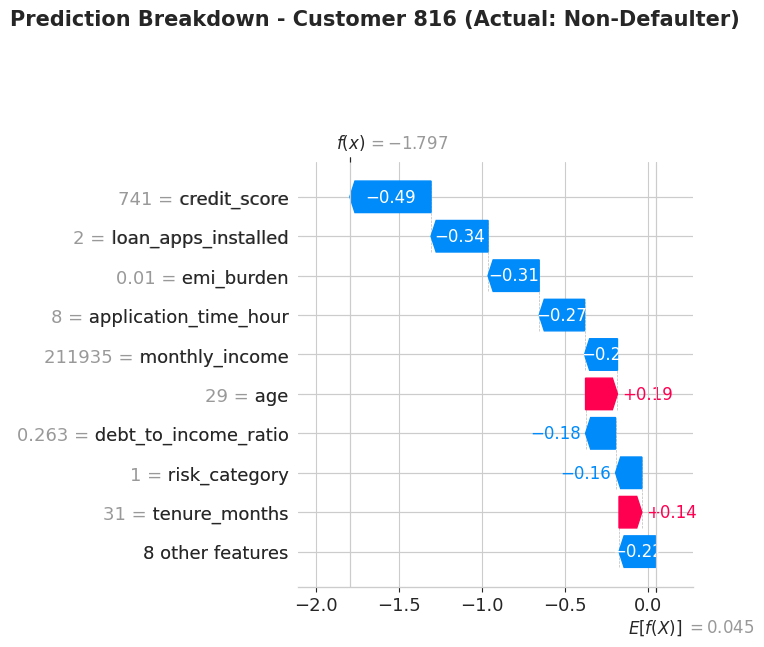


ALL VISUALIZATIONS COMPLETE!


In [20]:
# --- PRESENTATION-READY VISUALIZATIONS WITH CLEAN SPACING ---
import numpy as np
import shap
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import HTML, display
from sklearn.metrics import confusion_matrix, roc_curve, precision_recall_curve, auc

plt.close('all')
sns.set_style("whitegrid")
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "font.size": 12,
    "axes.titlesize": 16,
    "axes.labelsize": 13,
})

SPACER = HTML("<div style='height:55px'></div>")

def show_plot(fig):
    """Show one figure and add extra vertical spacing in Colab output."""
    fig.tight_layout(pad=2.0)
    plt.show()
    display(SPACER)
    plt.close(fig)

print("=" * 60)
print("GENERATING PRESENTATION-READY VISUALIZATIONS")
print("=" * 60)

# 1. Confusion Matrix
print("\n1. CONFUSION MATRIX")
print("-" * 60)
fig, ax = plt.subplots(figsize=(8, 6))
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Defaulter', 'Defaulter'],
    yticklabels=['Non-Defaulter', 'Defaulter'],
    ax=ax,
)
ax.set_xlabel('Predicted', fontweight='bold')
ax.set_ylabel('Actual', fontweight='bold')
ax.set_title('Confusion Matrix - Test Set', fontweight='bold', pad=18)
show_plot(fig)

# 2. ROC Curve
print("\n2. ROC CURVE")
print("-" * 60)
fig, ax = plt.subplots(figsize=(8, 6))
fpr, tpr, _ = roc_curve(y_test, y_test_prob)
roc_auc = auc(fpr, tpr)
ax.plot(fpr, tpr, color='darkorange', lw=2.5, label=f'ROC Curve (AUC = {roc_auc:.4f})')
ax.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('Receiver Operating Characteristic (ROC) Curve', fontweight='bold', pad=18)
ax.legend(loc='lower right')
show_plot(fig)

# 3. Precision-Recall Curve
print("\n3. PRECISION-RECALL CURVE")
print("-" * 60)
fig, ax = plt.subplots(figsize=(8, 6))
precision, recall, _ = precision_recall_curve(y_test, y_test_prob)
pr_auc = auc(recall, precision)
ax.plot(recall, precision, color='royalblue', lw=2.5, label=f'PR Curve (AUC = {pr_auc:.4f})')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve', fontweight='bold', pad=18)
ax.legend(loc='lower left')
show_plot(fig)

# SHAP values for class 1 / default risk
print("\n4. SHAP EXPLANATIONS")
print("-" * 60)
explainer = shap.TreeExplainer(final_model)
raw_shap_values = explainer.shap_values(X_test)
raw_base_value = explainer.expected_value

if isinstance(raw_shap_values, list):
    shap_values = raw_shap_values[1]
else:
    shap_values = raw_shap_values

if isinstance(raw_base_value, (list, np.ndarray)):
    base_value = raw_base_value[1] if len(raw_base_value) > 1 else raw_base_value[0]
else:
    base_value = raw_base_value

# 4A. SHAP Feature Importance Bar Plot
print("\n4A. TOP 10 FEATURE IMPORTANCE (SHAP)")
plt.figure(figsize=(10, 7))
shap.summary_plot(shap_values, X_test, plot_type='bar', max_display=10, show=False)
fig = plt.gcf()
ax = plt.gca()
ax.set_title('Top 10 Features Driving Default Predictions', fontweight='bold', pad=18)
ax.set_xlabel('Average Impact on Model Output (|SHAP value|)')
fig.tight_layout(pad=2.0)
plt.show()
display(SPACER)
plt.close(fig)

# 4B. SHAP Beeswarm Plot
print("\n4B. FEATURE IMPACT DIRECTION")
plt.figure(figsize=(10, 7))
shap.summary_plot(shap_values, X_test, max_display=10, show=False)
fig = plt.gcf()
ax = plt.gca()
ax.set_title('How Features Affect Default Risk', fontweight='bold', pad=18)
ax.set_xlabel('SHAP Value (Impact on Model Output)')
fig.tight_layout(pad=2.0)
plt.show()
display(SPACER)
plt.close(fig)

# 5. Individual Prediction Waterfall Plots
print("\n5. INDIVIDUAL PREDICTION BREAKDOWNS")
print("-" * 60)
feature_names = X_test.columns.tolist()
defaulter_idx = np.where(y_test.to_numpy() == 1)[0][0]
non_defaulter_idx = np.where(y_test.to_numpy() == 0)[0][0]
examples = [
    (defaulter_idx, 'Defaulter'),
    (non_defaulter_idx, 'Non-Defaulter'),
]

for row_idx, actual_label in examples:
    customer_id = X_test.index[row_idx]
    predicted_probability = y_test_prob[row_idx]
    print(f"\nCustomer {customer_id} | Actual: {actual_label} | Predicted default probability: {predicted_probability:.1%}")

    explanation = shap.Explanation(
        values=shap_values[row_idx],
        base_values=base_value,
        data=X_test.iloc[row_idx].values,
        feature_names=feature_names,
    )

    plt.figure(figsize=(11, 6.5))
    shap.plots.waterfall(explanation, max_display=10, show=False)
    fig = plt.gcf()
    fig.suptitle(
        f'Prediction Breakdown - Customer {customer_id} (Actual: {actual_label})',
        fontsize=15,
        fontweight='bold',
        y=1.03,
    )
    fig.tight_layout(pad=2.5)
    plt.show()
    display(SPACER)
    plt.close(fig)

plt.close('all')
print("\n" + "=" * 60)
print("ALL VISUALIZATIONS COMPLETE!")
print("=" * 60)



# 5. probability and risk score display

In [21]:
# --- STEP 6: PROBABILITY & RISK SCORE CALCULATOR ---
import numpy as np
import pandas as pd

print("="*60)
print("BUILDING PROBABILITY & RISK SCORE SYSTEM")
print("="*60)

# Function 1: Convert Probability to Risk Score (300-850 scale, like CIBIL)
def probability_to_risk_score(prob):
    """
    Converts default probability (0-1) to a risk score (300-850)
    Higher score = Lower risk (safer customer)
    Lower score = Higher risk (riskier customer)
    """
    risk_score = 850 - (prob * 550)
    return int(max(300, min(850, risk_score)))  # Clamp between 300-850

# Function 2: Assign Risk Category based on Score
def get_risk_category(score):
    if score >= 750:
        return "Very Low Risk", "✅ Approve - Excellent Customer", "green"
    elif score >= 650:
        return "Low Risk", "✅ Approve - Good Customer", "lightgreen"
    elif score >= 550:
        return "Medium Risk", "⚠️ Review - Moderate Risk", "orange"
    elif score >= 450:
        return "High Risk", "⚠️ Caution - High Risk", "orangered"
    else:
        return "Very High Risk", "❌ Reject - Very High Risk", "red"

# Apply to Test Set
print("\nApplying risk scoring to test set...")
test_risk_scores = [probability_to_risk_score(p) for p in y_test_prob]
test_risk_categories = [get_risk_category(s)[0] for s in test_risk_scores]
test_recommendations = [get_risk_category(s)[1] for s in test_risk_scores]

# Create results DataFrame (Added Original Credit Score)
results_df = pd.DataFrame({
    'Customer_ID': [f'CUST_{i:04d}' for i in range(len(y_test_prob))],
    'Actual_Status': ['Defaulter' if y == 1 else 'Non-Defaulter' for y in y_test],
    'Original_Credit_Score': X_test['credit_score'].values,  # <-- NEW: Original Score
    'Predicted_Probability': y_test_prob,
    'Model_Risk_Score': test_risk_scores,  # <-- Renamed for clarity
    'Risk_Category': test_risk_categories,
    'Recommendation': test_recommendations
})

print(f"✓ Risk scoring complete for {len(results_df)} customers")

# Display Summary Statistics
print("\n" + "="*60)
print("RISK DISTRIBUTION SUMMARY")
print("="*60)
risk_summary = results_df['Risk_Category'].value_counts()
for category, count in risk_summary.items():
    percentage = (count / len(results_df)) * 100
    print(f"{category:20s}: {count:3d} customers ({percentage:.1f}%)")

# Show Examples
print("\n" + "="*60)
print("SAMPLE CUSTOMER RISK ASSESSMENTS (Original vs Model Score)")
print("="*60)

# Show 5 diverse examples
sample_indices = [0, 50, 100, 150, 200]
for idx in sample_indices:
    if idx < len(results_df):
        row = results_df.iloc[idx]
        print(f"\nCustomer: {row['Customer_ID']}")
        print(f"  Actual Status: {row['Actual_Status']}")
        print(f"  Original Credit Score: {row['Original_Credit_Score']}")  # <-- NEW
        print(f"  Default Probability: {row['Predicted_Probability']:.1%}")
        print(f"  Model Risk Score: {row['Model_Risk_Score']} / 850")
        print(f"  Risk Category: {row['Risk_Category']}")
        print(f"  → {row['Recommendation']}")

# Save for Dashboard
results_df.to_csv('risk_assessment_results.csv', index=False)
print("\n" + "="*60)
print("✓ Risk assessment results saved to 'risk_assessment_results.csv'")
print("="*60)

BUILDING PROBABILITY & RISK SCORE SYSTEM

Applying risk scoring to test set...
✓ Risk scoring complete for 300 customers

RISK DISTRIBUTION SUMMARY
Medium Risk         : 101 customers (33.7%)
High Risk           :  75 customers (25.0%)
Very Low Risk       :  46 customers (15.3%)
Low Risk            :  43 customers (14.3%)
Very High Risk      :  35 customers (11.7%)

SAMPLE CUSTOMER RISK ASSESSMENTS (Original vs Model Score)

Customer: CUST_0000
  Actual Status: Non-Defaulter
  Original Credit Score: 741
  Default Probability: 14.2%
  Model Risk Score: 771 / 850
  Risk Category: Very Low Risk
  → ✅ Approve - Excellent Customer

Customer: CUST_0050
  Actual Status: Defaulter
  Original Credit Score: 547
  Default Probability: 73.6%
  Model Risk Score: 445 / 850
  Risk Category: Very High Risk
  → ❌ Reject - Very High Risk

Customer: CUST_0100
  Actual Status: Non-Defaulter
  Original Credit Score: 509
  Default Probability: 47.1%
  Model Risk Score: 591 / 850
  Risk Category: Medium Risk

# 6. default timer prediction


In [22]:
# --- DEFAULT TIMER PREDICTION (FIXED) ---
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("="*60)
print("BUILDING DEFAULT TIMER PREDICTION MODEL")
print("="*60)

# Filter only defaulters for regression model
defaulters_mask = y_train == 1
X_defaulters = X_train[defaulters_mask]
y_months = df.loc[X_defaulters.index, 'months_to_default'].dropna()

# Align indices
common_idx = X_defaulters.index.intersection(y_months.index)
X_defaulters = X_defaulters.loc[common_idx]
y_months = y_months.loc[common_idx]

print(f"Training on {len(X_defaulters)} defaulters with months_to_default data")

# Train regression model
timer_model = XGBRegressor(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.05,
    random_state=42,
    verbosity=0
)

timer_model.fit(X_defaulters, y_months)
print("✓ Default timer model trained successfully")

# Predict on test set defaulters
test_defaulters_mask = y_test == 1
X_test_defaulters = X_test[test_defaulters_mask]

if len(X_test_defaulters) > 0:
    predicted_months = timer_model.predict(X_test_defaulters)

    print("\n" + "="*60)
    print("DEFAULT TIMER PREDICTIONS (Sample)")
    print("="*60)

    # FIX: Use enumerate with range instead of dataframe index
    for i in range(min(5, len(X_test_defaulters))):
        # Get the actual index from the test set
        actual_idx = X_test_defaulters.index[i]

        # Use positional index i for y_test_prob
        prob = y_test_prob[actual_idx] if actual_idx < len(y_test_prob) else y_test_prob[i]
        months = predicted_months[i]

        print(f"Customer {actual_idx}:")
        print(f"  Default Probability: {prob:.1%}")
        print(f"  Predicted Months to Default: {months:.1f} months")
        print(f"  → Warning: High risk of default within {int(months)} months")

print("\n" + "="*60)
print("✓ Default timer system ready")
print("="*60)

BUILDING DEFAULT TIMER PREDICTION MODEL
Training on 251 defaulters with months_to_default data
✓ Default timer model trained successfully

DEFAULT TIMER PREDICTIONS (Sample)
Customer 484:
  Default Probability: 14.2%
  Predicted Months to Default: 5.2 months
  → Warning: High risk of default within 5 months
Customer 187:
  Default Probability: 26.6%
  Predicted Months to Default: 1.9 months
  → Warning: High risk of default within 1 months
Customer 570:
  Default Probability: 43.5%
  Predicted Months to Default: 5.1 months
  → Warning: High risk of default within 5 months
Customer 630:
  Default Probability: 66.2%
  Predicted Months to Default: 5.0 months
  → Warning: High risk of default within 5 months
Customer 796:
  Default Probability: 80.8%
  Predicted Months to Default: 2.5 months
  → Warning: High risk of default within 2 months

✓ Default timer system ready
